In [1]:
import numpy as np
import matplotlib.pyplot as plt
n = 1001
h_bar = 1.054 * 10**-34  # Planck's constant in J*s
e = 1.6 * 10**-19  # elementary charge in C
c0 = 3 * 10**8  # speed of light in m/s

## for $O_2$ molecule

In [ ]:
u = 1.660538921 * 10**(-27)  # atomic mass unit in kg
m_O = 15.999*u  # Mass of oxygen atom in kg
reduced_m = m_O*m_O/(m_O + m_O)  # Reduced mass for oxygen-oxygen system 

nu_bar = 1580.161  #(cm^-1) harmonic spectroscopic constant National Institute of Standards and Technology (NIST) 2022
omega = 2* np.pi * c0 * nu_bar * 100  # angular frequency in rad/s
a_osc = np.sqrt(h_bar / (reduced_m * omega))  # oscillator length in m

# Radial grid
rmax = 10 * a_osc
x = np.linspace(0, rmax, n)
delta_x = x[1] - x[0]
c = (h_bar**2) / (2*reduced_m *e*delta_x**2)

print("c =", c,", n =", n)

c = 981.0544101187332 , n = 1001


## Potential $V(r) = \frac{1}{2}m \omega^2 r^2$
also, u(r) = R*r (spherical)

In [3]:
v_har = (1/2) * reduced_m * omega**2 * x**2 /e  # harmonic oscillator potential
#pe = np.diag(v[1:-1])  # potential energy matrix
ke = (-c) * ( np.eye((n-2), k = 1) + (-2)*np.eye(n-2) + np.eye((n-2), k = -1) ) # kinetic energy matrix
x_new = x[1:-1]  # new r values corresponding to the eigenvectors
E_0 = h_bar*omega/(2*e)

In [5]:
num_states = 4
# Store energies for s-wave and p-wave
energy = np.zeros((num_states, 2))  # 2 columns for l=0 and l=1 (s and p waves)
u_r = np.zeros((n-2, num_states, 2))  # Store eigenvectors for l=0 and l=1
for l in [0, 1]:
    # Centrifugal potential (in eV)
    v_cent = (h_bar**2 * l*(l+1))/ (2 * reduced_m * x_new**2 * e)
    # Effective potential
    v_eff = v_har[1:-1] + v_cent
    pe = np.diag(v_eff)  # potential energy matrix
    
    Hamil = ke + pe     # Radial Schrodinger equation for the 3D isotropic harmonic oscillator
    eig_val, eig_vec = np.linalg.eigh(Hamil)  # Eig_vec will give us u(r) = r*R(r) where R(r) is the radial wavefunction

    energy[:, l] = eig_val[:num_states]
    print(f"Eigenvalues for l = {l}: {eig_val[:num_states]}")
    for k in range(num_states):
        E_theory = h_bar*omega*(2*k + l + 1.5)/e
        print(f"l = {l}, k = {k}, E_theory = {E_theory}, E_numerical = {eig_val[k]}, difference = {E_theory - eig_val[k]}")
        print(f"E_theory = {E_theory/E_0}, E_numerical = {eig_val[k]/E_0}")
        # Normalize the eigenvectors
        yp = eig_vec[:, k]**2  # u(r)^2, for kth eigenvector
        norm = np.sqrt(np.trapezoid(yp , x_new))
        u_r[:, k, l] = eig_vec[:, k] / norm  # normalized u(r) for kth eigenvector and l

Eigenvalues for l = 0: [0.29431326 0.68672276 1.07912245 1.47151232]
l = 0, k = 0, E_theory = 0.29431632303562, E_numerical = 0.29431325720594853, difference = 3.0658296714669575e-06
E_theory = 3.0, E_numerical = 2.999968749646912
l = 0, k = 1, E_theory = 0.6867380870831135, E_numerical = 0.6867227577590697, difference = 1.5329324043800163e-05
E_theory = 7.000000000000001, E_numerical = 6.999843746443769
l = 0, k = 2, E_theory = 1.0791598511306069, E_numerical = 1.0791224471242373, difference = 3.740400636953467e-05
E_theory = 11.000000000000002, E_numerical = 10.999618736677766
l = 0, k = 3, E_theory = 1.4715816151781003, E_numerical = 1.4715123249334139, difference = 6.92902446863819e-05
E_theory = 15.000000000000002, E_numerical = 14.999293716597453
Eigenvalues for l = 1: [0.49052332 0.88293315 1.27533317 1.66772337]
l = 1, k = 0, E_theory = 0.4905272050593667, E_numerical = 0.4905233217072378, difference = 3.883352128919437e-06
E_theory = 5.0, E_numerical = 4.999960416546841
l = 1,

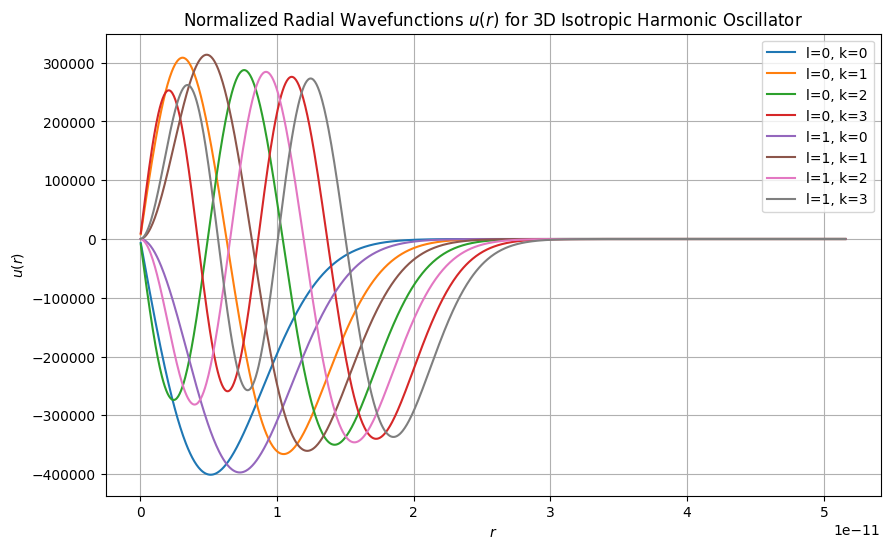

In [7]:
plt.figure(figsize=(10, 6))
for l in [0, 1]:
    for k in range(num_states):
        plt.plot(x_new, u_r[:, k, l], label=f"l={l}, k={k}")
plt.title("Normalized Radial Wavefunctions $u(r)$ for 3D Isotropic Harmonic Oscillator")
plt.xlabel("$r $")
plt.ylabel("$u(r)$")
plt.legend()
plt.grid()
plt.show()

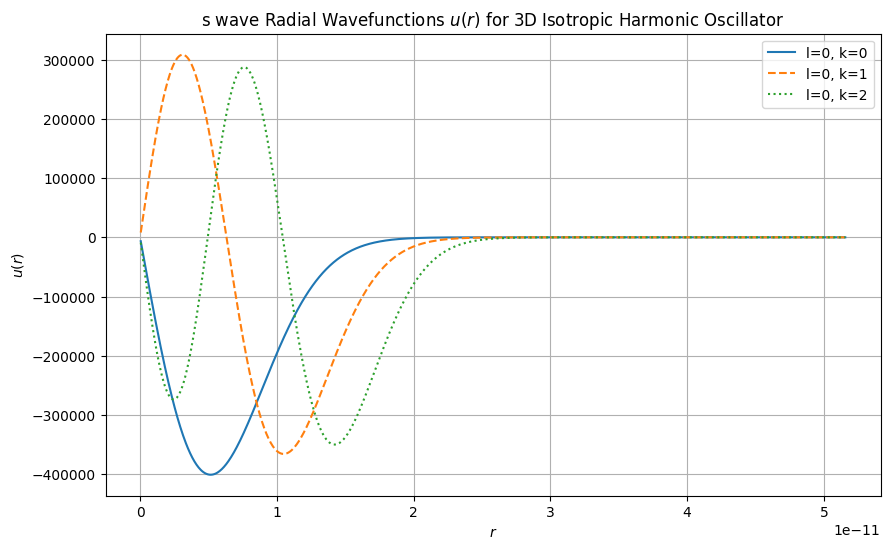

In [8]:
plt.figure(figsize=(10, 6))
plt.plot(x_new, u_r[:, 0, 0], label=f"l=0, k=0")
plt.plot(x_new, u_r[:, 1, 0], label=f"l=0, k=1", ls="--")
plt.plot(x_new, u_r[:, 2, 0], label=f"l=0, k=2",ls=":")
plt.title("s wave Radial Wavefunctions $u(r)$ for 3D Isotropic Harmonic Oscillator")
plt.xlabel("$r $")
plt.ylabel("$u(r)$")
plt.legend()
plt.grid()
plt.show()

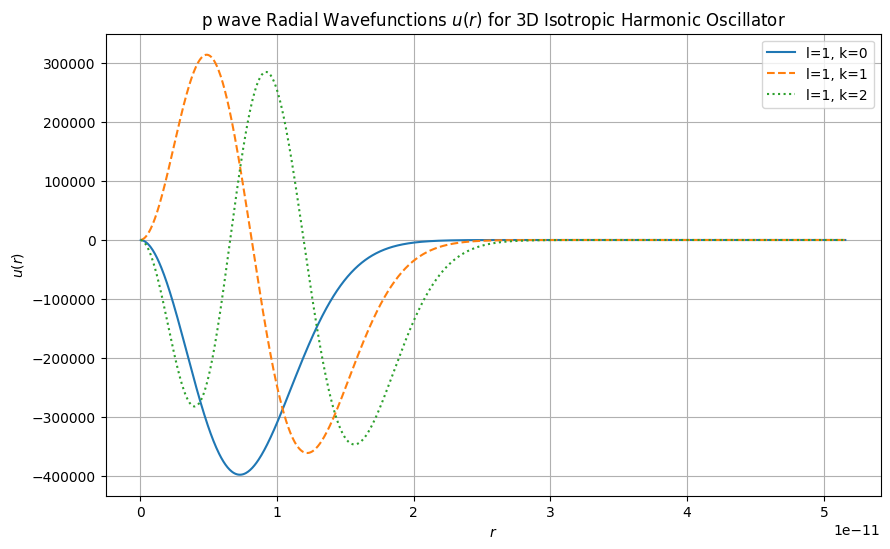

In [9]:
plt.figure(figsize=(10, 6))
plt.plot(x_new, u_r[:, 0, 1], label=f"l=1, k=0")
plt.plot(x_new, u_r[:, 1, 1], label=f"l=1, k=1", ls="--")
plt.plot(x_new, u_r[:, 2, 1], label=f"l=1, k=2", ls=":")
plt.title("p wave Radial Wavefunctions $u(r)$ for 3D Isotropic Harmonic Oscillator")
plt.xlabel("$r $")
plt.ylabel("$u(r)$")
plt.legend()
plt.grid()
plt.show()

In [11]:
R_r = u_r / x_new[:, np.newaxis, np.newaxis]  # R(r) = u(r)/r

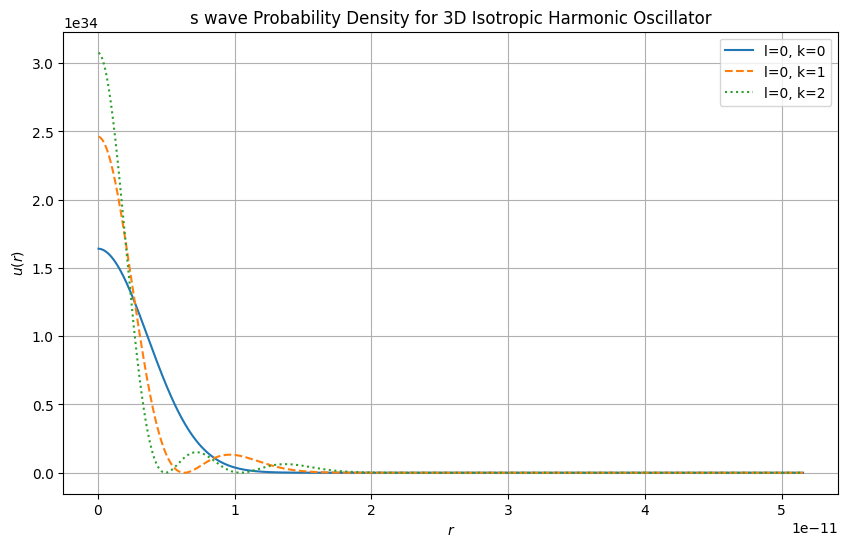

In [12]:
plt.figure(figsize=(10, 6))
plt.plot(x_new, R_r[:, 0, 0]**2, label=f"l=0, k=0")
plt.plot(x_new, R_r[:, 1, 0]**2, label=f"l=0, k=1", ls="--")
plt.plot(x_new, R_r[:, 2, 0]**2, label=f"l=0, k=2", ls=":")
plt.title("s wave Probability Density for 3D Isotropic Harmonic Oscillator")
plt.xlabel("$r $")
plt.ylabel("$u(r)$")
plt.legend()
plt.grid()
plt.show()

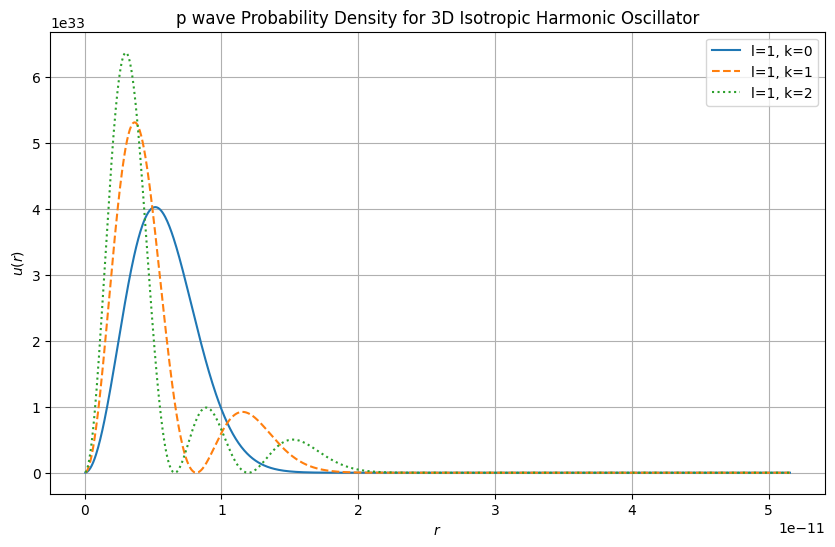

In [13]:
plt.figure(figsize=(10, 6))
plt.plot(x_new, R_r[:, 0, 1]**2, label=f"l=1, k=0")
plt.plot(x_new, R_r[:, 1, 1]**2, label=f"l=1, k=1", ls="--")
plt.plot(x_new, R_r[:, 2, 1]**2, label=f"l=1, k=2", ls=":")
plt.title("p wave Probability Density for 3D Isotropic Harmonic Oscillator")
plt.xlabel("$r $")
plt.ylabel("$u(r)$")
plt.legend()
plt.grid()
plt.show()